# ACIT4620 Group 1 — Notebook 09
## Matched Validation Comparison: EfficientNet-B0, Linear, MLP, and First-Order Sugeno ANFIS

**Research basis:** Submitted seven-class HAM10000 proposal. **No new training and no held-out test evaluation.** This notebook compares completed models from E2a-50, E3, and E4 on the **same 1,441 validation images / 1,067 lesions**. It recomputes scores from *saved per-image predictions*, not manually typed results.

**Primary outcome:** Seven-class macro-F1. Secondary: accuracy, balanced accuracy, melanoma precision/recall, per-class F1, macro OvR AUROC/AP. Exploratory paired lesion-bootstrap uncertainty is **conditional on trained and validation-selected checkpoints**; it does not establish out-of-sample significance.

Folder layout: `model_comparison.py`, `inputs/` (portable preverified exports), `outputs/` (generated).


### 1. Environment and input integrity
Use the same `.venv` Python interpreter that ran E3/E4 in VS Code. This analysis uses NumPy, pandas, scikit-learn, and matplotlib and can run on CPU.

In [1]:
import sys
print("Current Python:", sys.executable)

Current Python: c:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_09_Model_Comparison_VSCode_Complete\.venv\Scripts\python.exe


In [2]:
from pathlib import Path
import sys, numpy as np, pandas as pd, sklearn
from model_comparison import locate_root, verify_sources

ROOT = locate_root()
print('Python:', sys.executable)
print('Root:',ROOT)
print('NumPy:',np.__version__,'scikit-learn:',sklearn.__version__)
input_provenance = verify_sources(ROOT)
print('PASS:',len(input_provenance['files']),'input files have verified SHA-256 hashes.')
print('Split:',input_provenance['split_sha256'])
print('No test labels or predictions are included.')

Python: c:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_09_Model_Comparison_VSCode_Complete\.venv\Scripts\python.exe
Root: C:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_09_Model_Comparison_VSCode_Complete\ACIT4620_09_Model_Comparison_VSCode
NumPy: 2.5.4 scikit-learn: 1.9.1
PASS: 21 input files have verified SHA-256 hashes.
Split: 265ec2412f4dd7d50c75b46d75a095c0d3445250895b90b91f3d73aca9aebce0
No test labels or predictions are included.


### 2. Recheck matched validation image IDs and class order
All 16 prediction exports (1 CNN, 6 E3, 9 E4) must have identical `image_id`, `lesion_id`, and `true_dx` after sorting. Model-specific classes and predicted indices are checked against probabilities.

In [3]:
from model_comparison import load_predictions, metrics_and_classwise, verify_reported_metrics

predictions, reference, diagnostics = load_predictions(ROOT)
model_metrics, per_class = metrics_and_classwise(predictions)
verify_reported_metrics(ROOT,model_metrics)
print('PASS:',len(predictions),'models,',len(reference),'identical validation images,',reference.lesion_id.nunique(),'lesions')
display(model_metrics[['model','accuracy','macro_f1','balanced_accuracy','melanoma_recall']].round(4))

PASS: 16 models, 1441 identical validation images, 1067 lesions


,model,accuracy,macro_f1,balanced_accuracy,melanoma_recall
0,cnn_e2a50,0.7321,0.5500,0.6217,0.4315
1,linear_seed42,0.7065,0.5455,0.6317,0.4452
2,linear_seed52,0.7002,0.5421,0.6138,0.3904
3,linear_seed62,0.7009,0.5373,0.6235,0.4658
4,mlp_seed42,0.7550,0.5749,0.5832,0.4247
5,mlp_seed52,0.7502,0.5559,0.5974,0.4932
6,mlp_seed62,0.7189,0.5508,0.5816,0.4932
7,anfis_r4_seed42,0.7335,0.5458,0.6069,0.5137
8,anfis_r4_seed52,0.7446,0.5499,0.5748,0.4315
9,anfis_r4_seed62,0.7245,0.5431,0.6097,0.5000


### 3. Compare repeated seeds and validation-selected checkpoints
Three seed runs per linear, MLP, and ANFIS rule-count family. Mean ± sample standard deviation reflects seed-to-seed variation. Best-seed checkpoints were selected *using validation macro-F1*, so these are not unbiased test scores.

In [4]:
from model_comparison import seed_table, selected_checkpoints
seed_results=seed_table(model_metrics)
selected=selected_checkpoints(model_metrics)
display(seed_results.round(4))
display(selected[['family','model','accuracy','macro_f1','balanced_accuracy','melanoma_recall','melanoma_tp','melanoma_fn']].round(4))

,family,n_seeds,macro_f1_mean,macro_f1_sd,accuracy_mean,accuracy_sd,balanced_accuracy_mean,balanced_accuracy_sd,melanoma_recall_mean,melanoma_recall_sd
0,linear,3,0.5417,0.0041,0.7025,0.0034,0.6230,0.0090,0.4338,0.0389
1,mlp,3,0.5605,0.0127,0.7414,0.0196,0.5874,0.0087,0.4703,0.0395
2,anfis_r4,3,0.5462,0.0034,0.7342,0.0101,0.5971,0.0194,0.4817,0.0440
3,anfis_r8,3,0.5509,0.0078,0.7257,0.0083,0.5879,0.0135,0.4475,0.0672
4,anfis_r16,3,0.5430,0.0215,0.7143,0.0107,0.6062,0.0257,0.4749,0.0285


,family,model,accuracy,macro_f1,balanced_accuracy,melanoma_recall,melanoma_tp,melanoma_fn
0,cnn_e2a50,cnn_e2a50,0.7321,0.5500,0.6217,0.4315,63,83
1,linear,linear_seed42,0.7065,0.5455,0.6317,0.4452,65,81
2,mlp,mlp_seed42,0.7550,0.5749,0.5832,0.4247,62,84
3,anfis_r4,anfis_r4_seed52,0.7446,0.5499,0.5748,0.4315,63,83
4,anfis_r8,anfis_r8_seed42,0.7349,0.5588,0.5989,0.3699,54,92
5,anfis_r16,anfis_r16_seed52,0.7266,0.5676,0.6205,0.4521,66,80


### 4. Analyze per-class recall and paired prediction disagreements
The dataset is imbalanced; specifically inspect melanoma false negatives, and rare `df`, `vasc`, and `akiec` classes. Paired error overlap shows cases corrected versus lost between models.

In [5]:
from model_comparison import paired_error_table
err=paired_error_table(predictions,selected,reference)
sel_classes=per_class[per_class.model.isin(selected.model)].copy()
display(sel_classes.pivot(index='model',columns='class',values='recall').reindex(index=selected.model).round(3))
display(err.query("(model_a == 'anfis_r16_seed52' or model_b == 'anfis_r16_seed52')").head(10))

class,akiec,bcc,bkl,df,mel,nv,vasc
model,,,,,,,
cnn_e2a50,0.559,0.618,0.631,0.444,0.432,0.811,0.857
linear_seed42,0.618,0.562,0.607,0.556,0.445,0.777,0.857
mlp_seed42,0.441,0.539,0.607,0.444,0.425,0.863,0.762
anfis_r4_seed52,0.353,0.652,0.661,0.333,0.432,0.832,0.762
anfis_r8_seed42,0.412,0.584,0.649,0.444,0.370,0.829,0.905
anfis_r16_seed52,0.500,0.618,0.679,0.444,0.452,0.794,0.857


,model_a,model_b,disagreement_images,both_correct,both_wrong,a_only_correct,b_only_correct,a_melanoma_tp,b_melanoma_tp,melanoma_corrected_b_vs_a,melanoma_lost_b_vs_a
10,anfis_r16_seed52,cnn_e2a50,288,945,284,102,110,66,63,11,14
11,anfis_r16_seed52,linear_seed42,320,909,285,138,109,66,65,13,14
12,anfis_r16_seed52,mlp_seed42,281,961,267,86,127,66,62,13,17
13,anfis_r16_seed52,anfis_r4_seed52,250,963,284,84,110,66,63,9,12
14,anfis_r16_seed52,anfis_r8_seed42,271,949,284,98,110,66,54,7,19


### 5. Exploratory class-stratified lesion-level paired bootstrap
Resample **lesion IDs**, not individual image rows, within each diagnosis; all images belonging to a lesion move together. Report delta macro-F1 and percentile 95% intervals. Intervals include validation-model-selection bias, so do not call a model superior solely because a selected point estimate is higher.

In [6]:
from model_comparison import paired_cluster_bootstrap
PAIRS = [
    ('mlp_seed42','anfis_r16_seed52'),
    ('linear_seed42','anfis_r16_seed52'),
    ('cnn_e2a50','mlp_seed42'),
    ('cnn_e2a50','anfis_r16_seed52'),
    ('mlp_seed42','anfis_r8_seed42'),
]
paired_ci = paired_cluster_bootstrap(predictions,reference,PAIRS,n_boot=1200,seed=20261109)
display(paired_ci[['model_a','model_b','delta_b_minus_a_macro_f1','ci95_low','ci95_high','interval_includes_zero']].round(4))

,model_a,model_b,delta_b_minus_a_macro_f1,ci95_low,ci95_high,interval_includes_zero
0,mlp_seed42,anfis_r16_seed52,-0.0073,-0.0533,0.0485,True
1,linear_seed42,anfis_r16_seed52,0.0221,-0.0222,0.0638,True
2,cnn_e2a50,mlp_seed42,0.0249,-0.0218,0.0660,True
3,cnn_e2a50,anfis_r16_seed52,0.0176,-0.0330,0.0711,True
4,mlp_seed42,anfis_r8_seed42,-0.0161,-0.0779,0.0590,True


### 6. Produce validated tables, figures and a reproducibility ZIP
This calls the same independent verification and comparison workflow and exports all results as lightweight CSV/PNG/JSON. It also includes recorded head-only training time (not a matched end-to-end latency test).

In [7]:
from model_comparison import run_analysis
report = run_analysis(ROOT,n_boot=1200,seed=20261109)
print('Complete! ZIP:',ROOT/'outputs'/'ACIT4620_09_Validation_Comparison_Outputs.zip')

VERIFIED: 16 prediction exports, same 1441 images, 1067 lesions, E2a-50 fingerprint

SELECTED CHECKPOINTS:
           model  accuracy  macro_f1  balanced_accuracy  melanoma_recall
       cnn_e2a50    0.7321    0.5500             0.6217           0.4315
   linear_seed42    0.7065    0.5455             0.6317           0.4452
      mlp_seed42    0.7550    0.5749             0.5832           0.4247
 anfis_r4_seed52    0.7446    0.5499             0.5748           0.4315
 anfis_r8_seed42    0.7349    0.5588             0.5989           0.3699
anfis_r16_seed52    0.7266    0.5676             0.6205           0.4521

THREE-SEED SUMMARY:
   family  macro_f1_mean  macro_f1_sd  balanced_accuracy_mean  melanoma_recall_mean
   linear         0.5417       0.0041                  0.6230                0.4338
      mlp         0.5605       0.0127                  0.5874                0.4703
 anfis_r4         0.5462       0.0034                  0.5971                0.4817
 anfis_r8         0.5509 

### 7. Inspect figures and results

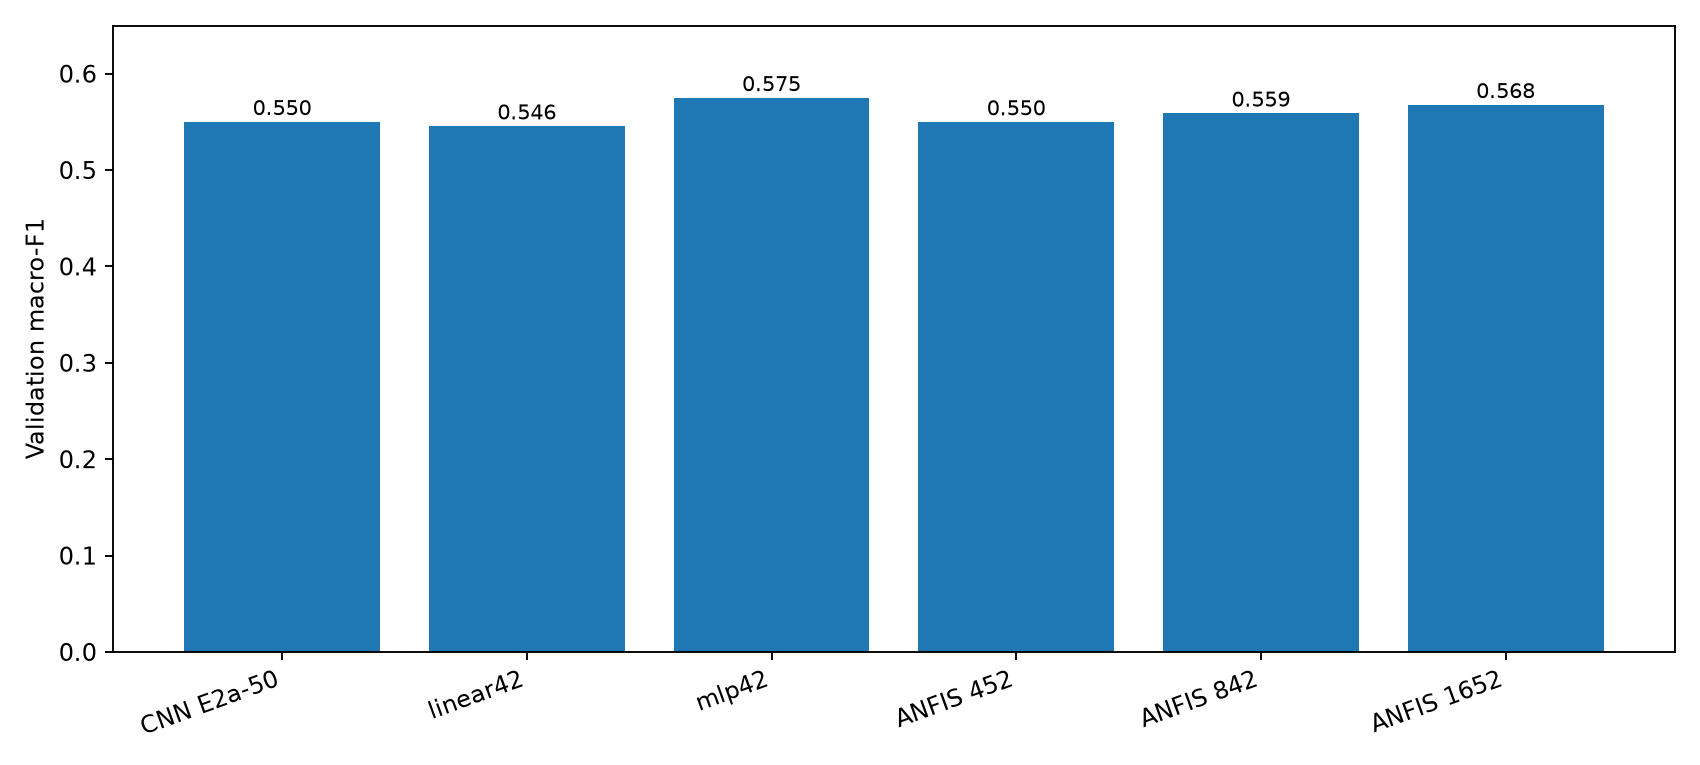

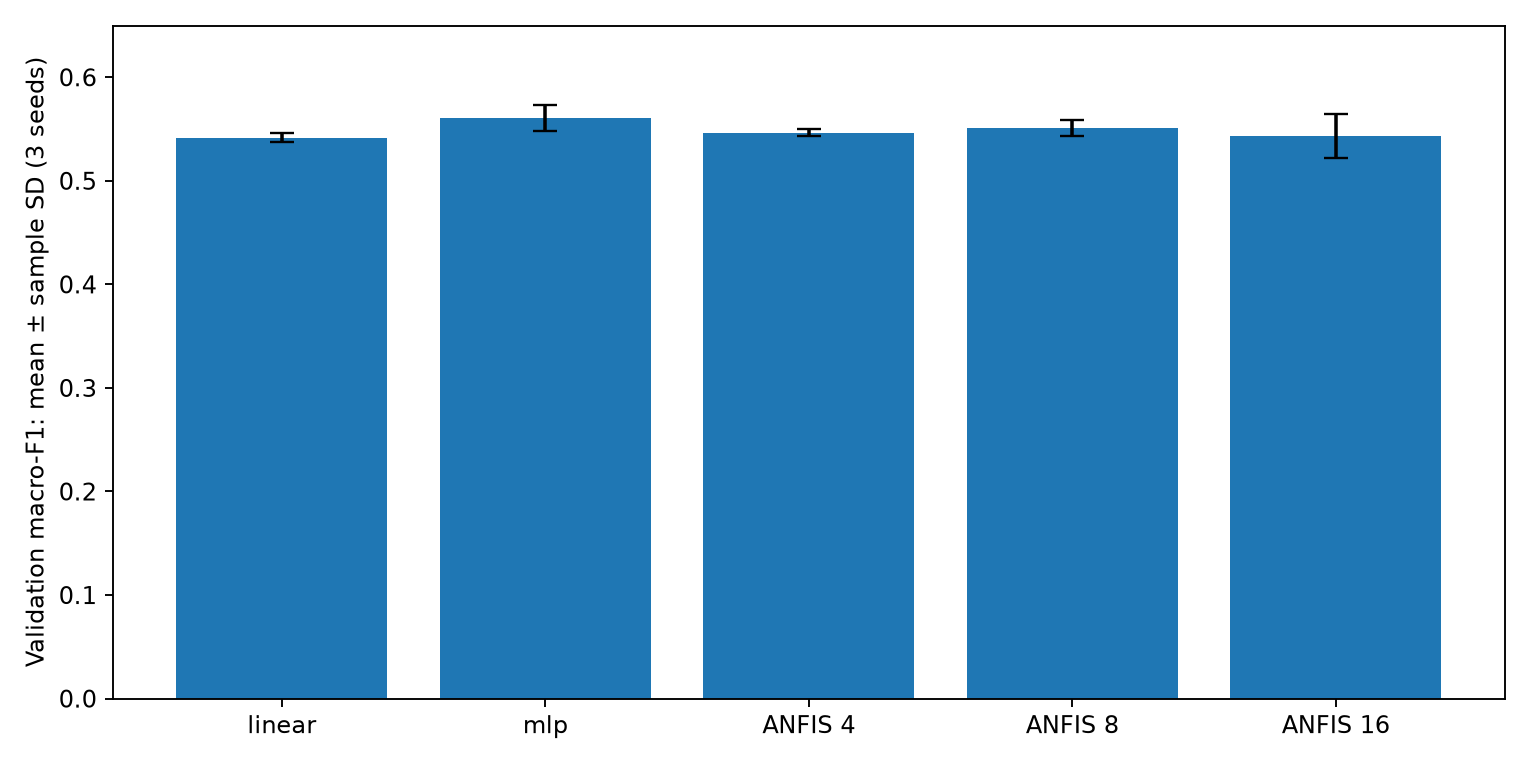

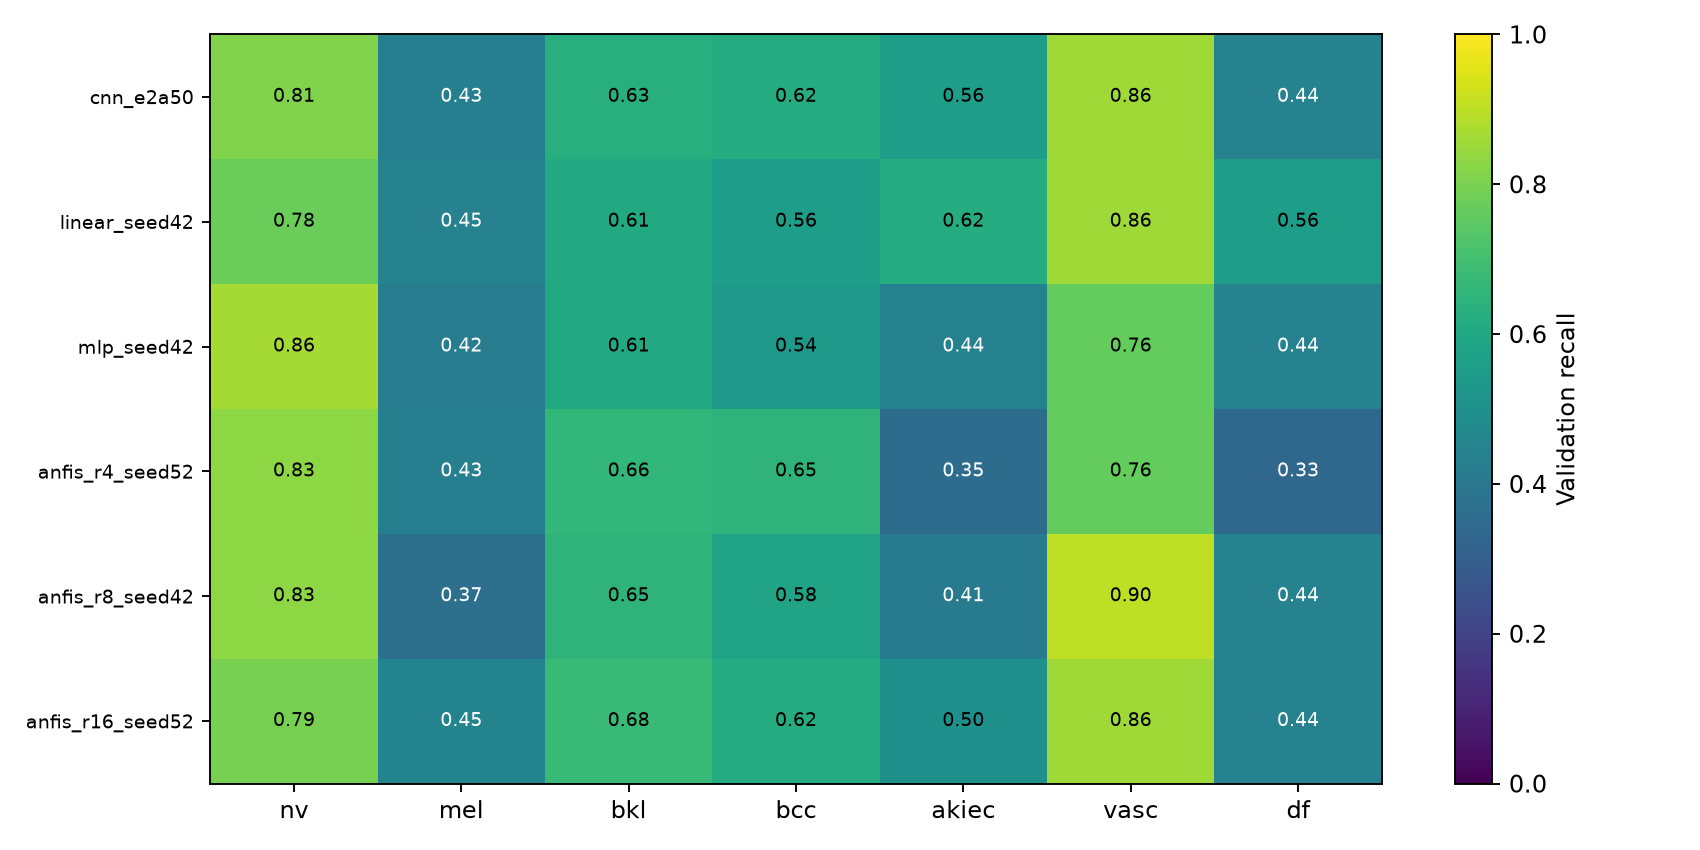

In [8]:
from IPython.display import display, Image
for file in ['selected_macro_f1.png','three_seed_macro_f1.png','selected_per_class_recall.png']:
    display(Image(filename=str(report['output_dir']/file)))

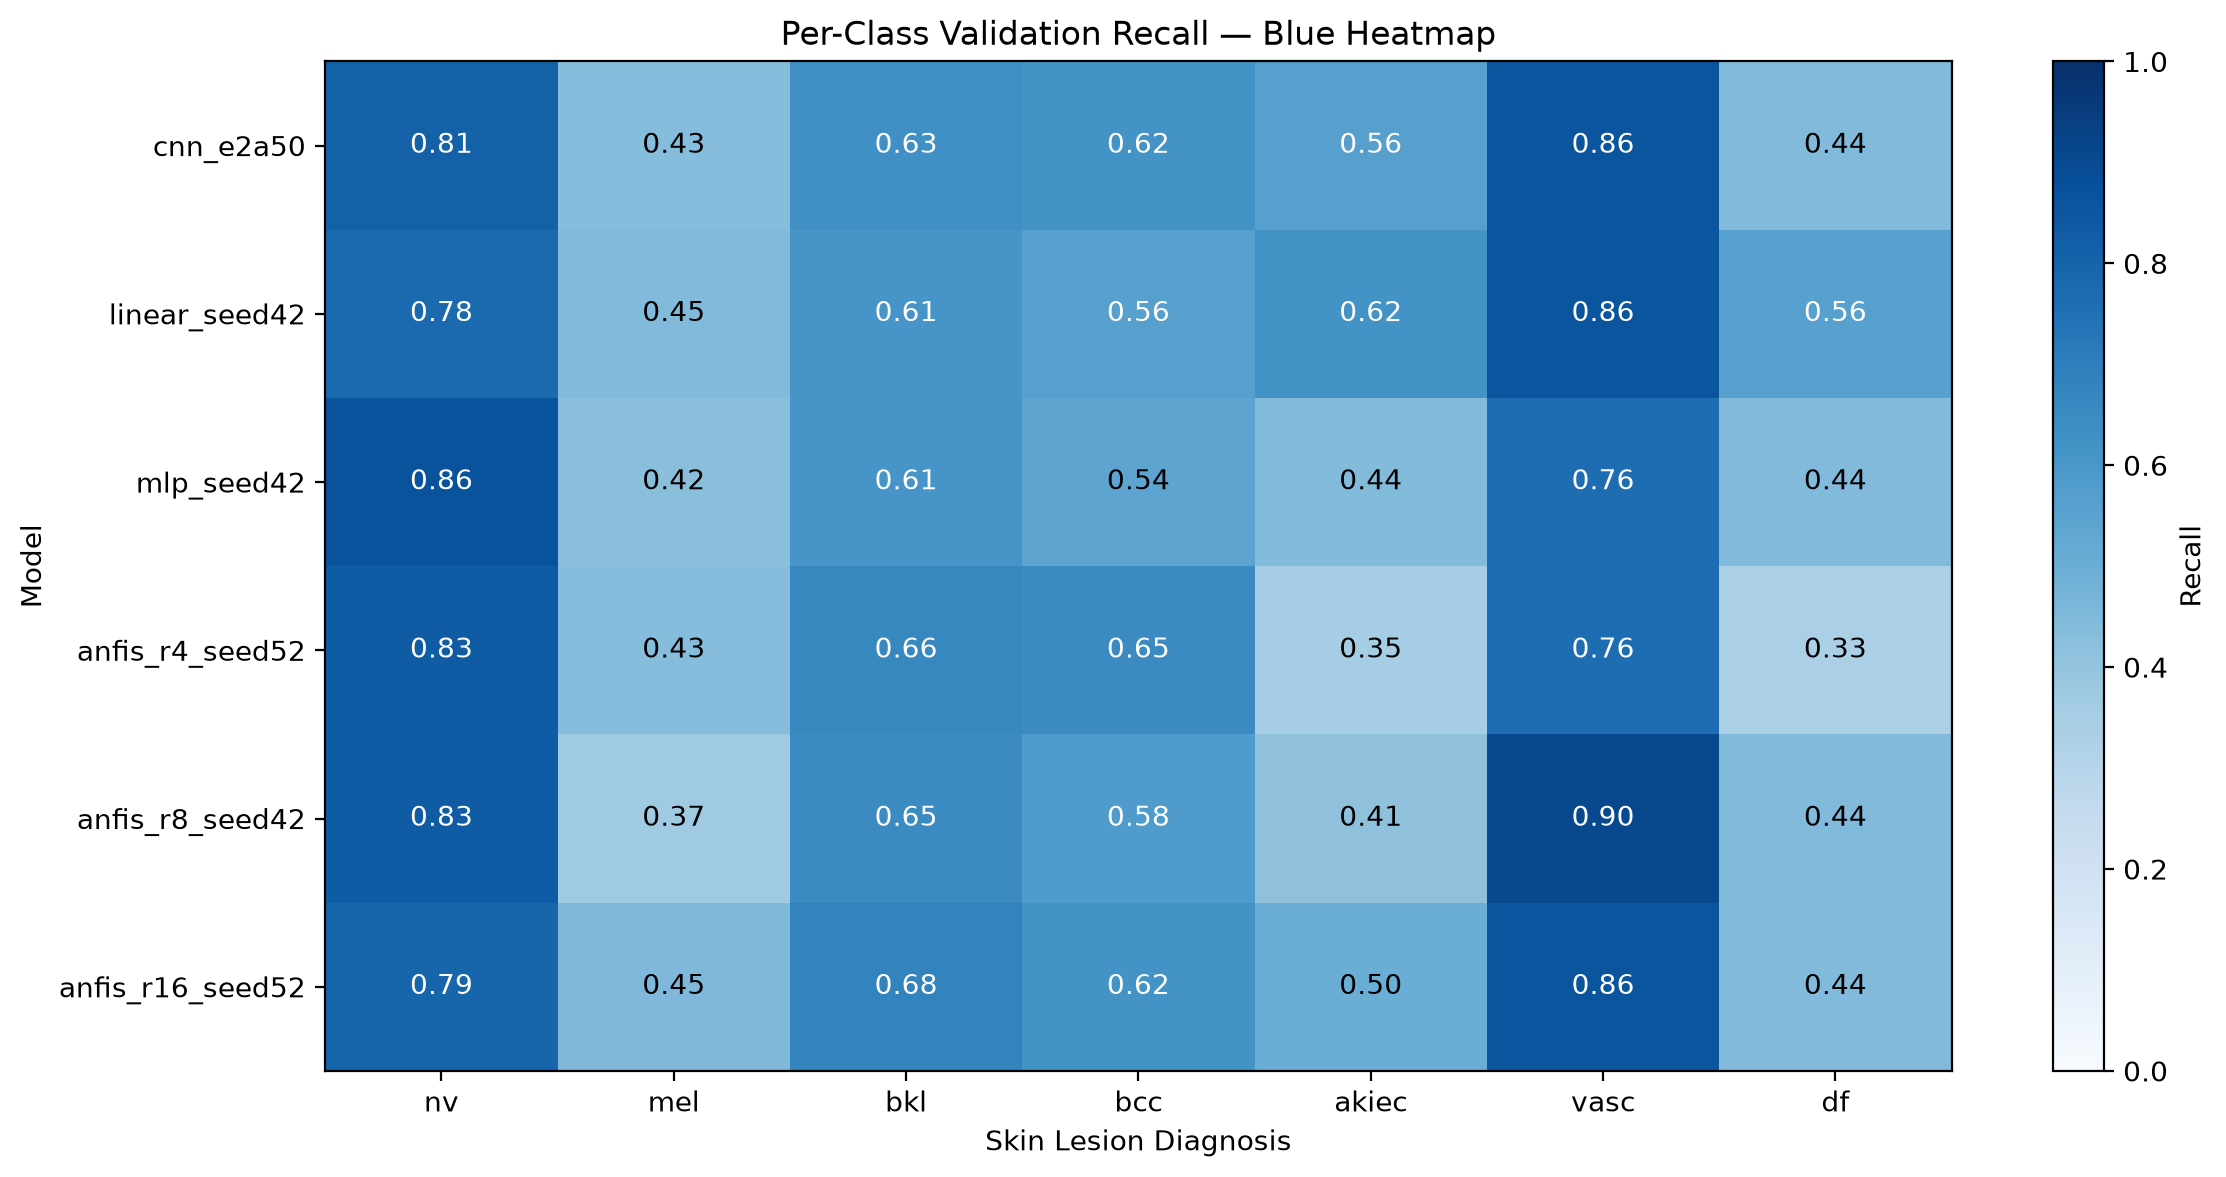

Saved: C:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_09_Model_Comparison_VSCode_Complete\ACIT4620_09_Model_Comparison_VSCode\outputs\ACIT4620_09_Validation_Comparison\additional_figures\01_blue_recall_heatmap.png


In [9]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

NEW_FIGURES = (
    ROOT / "outputs" /
    "ACIT4620_09_Validation_Comparison" /
    "additional_figures"
)
NEW_FIGURES.mkdir(parents=True, exist_ok=True)

CLASSES = ["nv", "mel", "bkl", "bcc", "akiec", "vasc", "df"]

models = selected["model"].tolist()

heat = (
    sel_classes.pivot(
        index="model",
        columns="class",
        values="recall"
    )
    .reindex(index=models, columns=CLASSES)
)

assert not heat.isna().any().any()

fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(
    heat.values,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yticks(range(len(models)), models)

for i in range(len(models)):
    for j in range(len(CLASSES)):
        value = heat.iloc[i, j]
        ax.text(
            j, i, f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value > 0.55 else "black"
        )

ax.set_title("Per-Class Validation Recall — Blue Heatmap")
ax.set_xlabel("Skin Lesion Diagnosis")
ax.set_ylabel("Model")

fig.colorbar(im, ax=ax, label="Recall")
fig.tight_layout()

path = NEW_FIGURES / "01_blue_recall_heatmap.png"
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(path)))
print("Saved:", path)


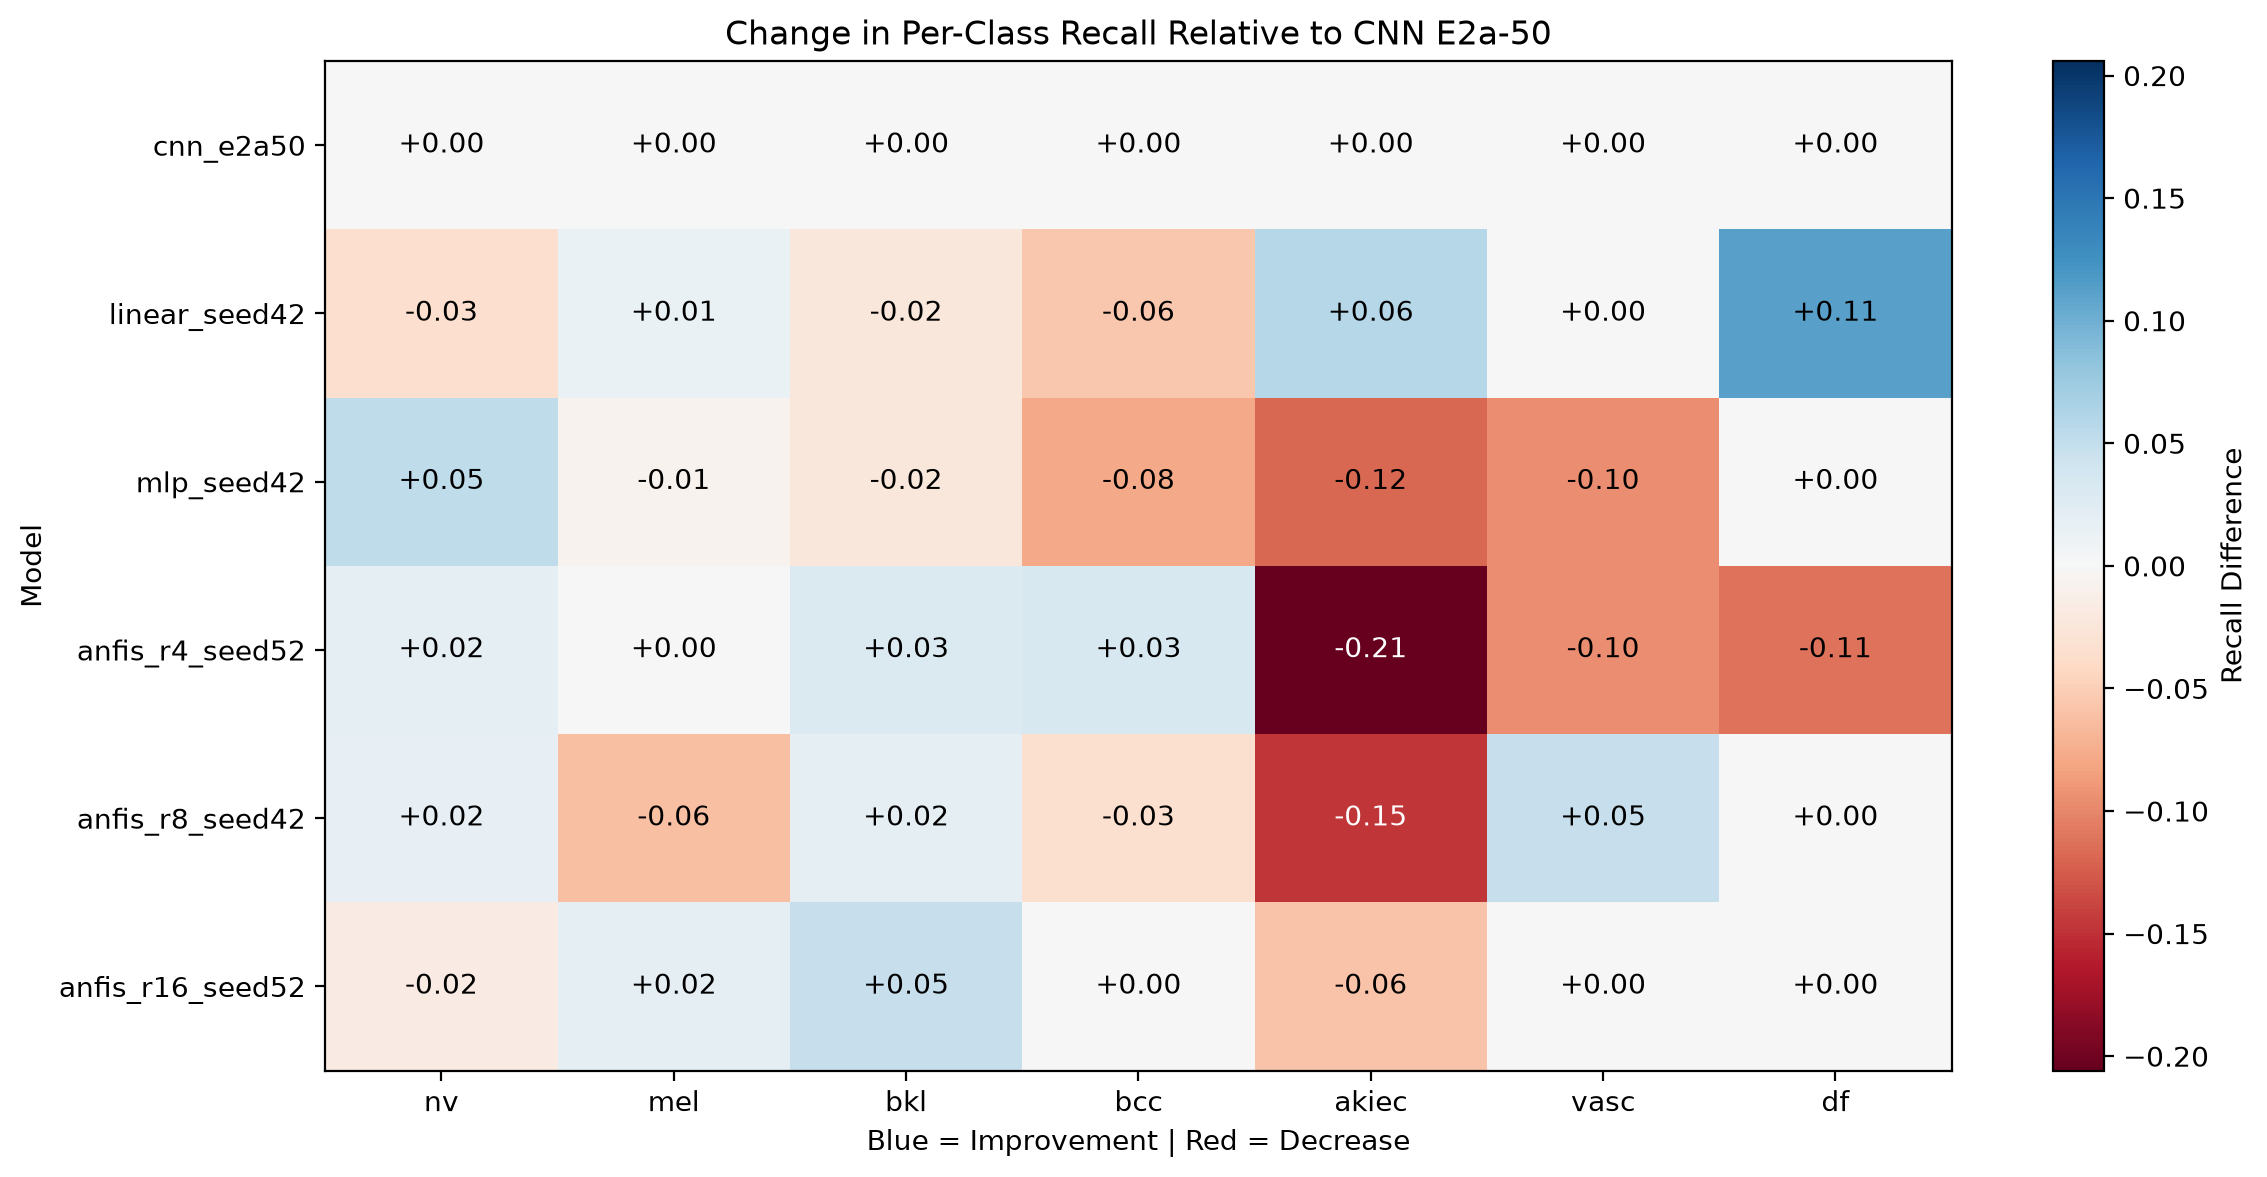

Saved: C:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_09_Model_Comparison_VSCode_Complete\ACIT4620_09_Model_Comparison_VSCode\outputs\ACIT4620_09_Validation_Comparison\additional_figures\02_recall_improvement_heatmap.png


In [10]:

from matplotlib.colors import TwoSlopeNorm

baseline = heat.loc["cnn_e2a50"]
delta = heat.subtract(baseline, axis=1)

limit = max(
    float(np.abs(delta.values).max()),
    0.01
)

fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(
    delta.values,
    cmap="RdBu",
    norm=TwoSlopeNorm(
        vmin=-limit,
        vcenter=0,
        vmax=limit
    ),
    aspect="auto"
)

ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_yticks(range(len(models)), models)

for i in range(len(models)):
    for j in range(len(CLASSES)):
        value = delta.iloc[i, j]
        ax.text(
            j, i, f"{value:+.2f}",
            ha="center",
            va="center",
            color=(
                "white"
                if abs(value) > 0.65 * limit
                else "black"
            )
        )

ax.set_title(
    "Change in Per-Class Recall Relative to CNN E2a-50"
)
ax.set_xlabel(
    "Blue = Improvement | Red = Decrease"
)
ax.set_ylabel("Model")

fig.colorbar(
    im, ax=ax,
    label="Recall Difference"
)

fig.tight_layout()

path = NEW_FIGURES / "02_recall_improvement_heatmap.png"
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(path)))
print("Saved:", path)


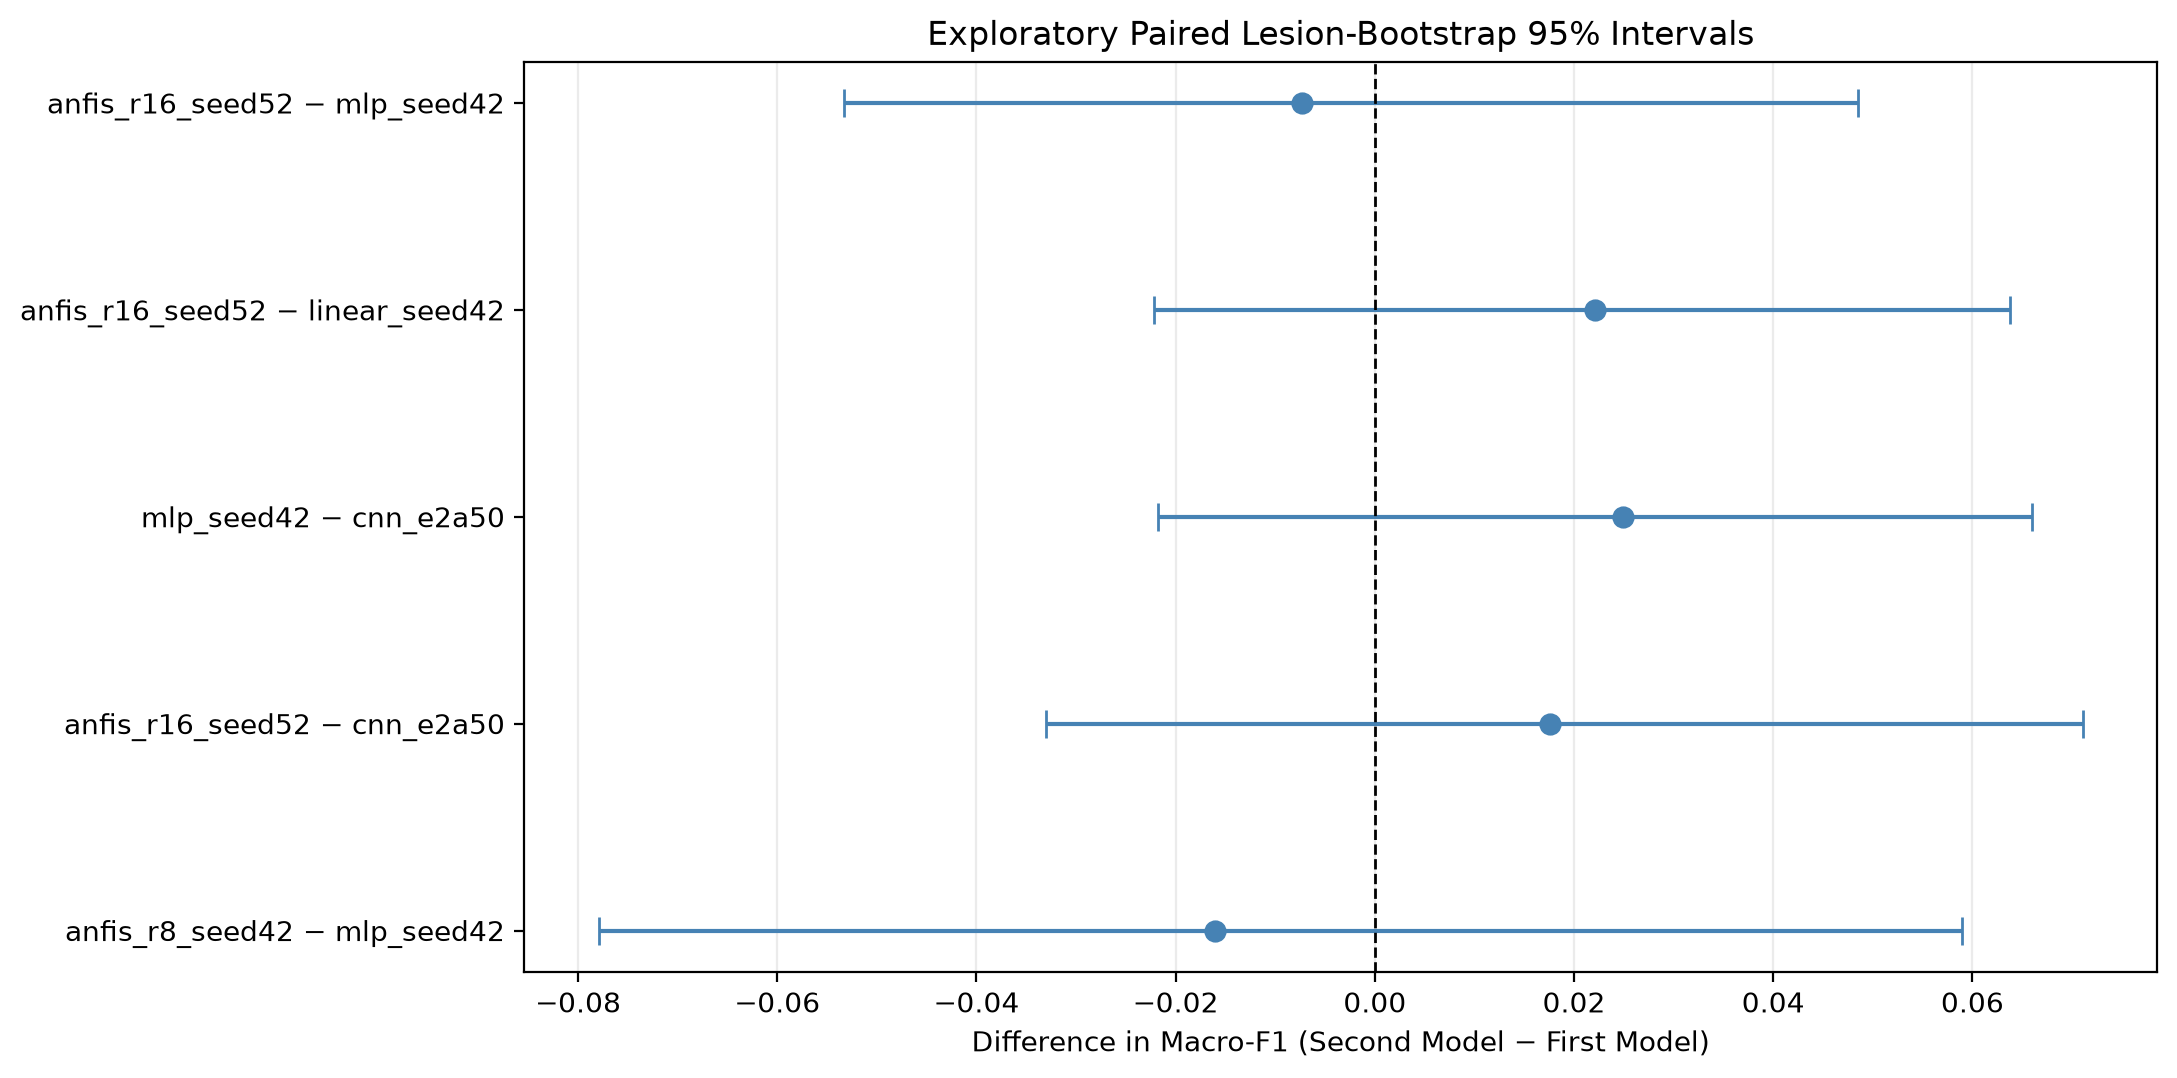

Saved: C:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_09_Model_Comparison_VSCode_Complete\ACIT4620_09_Model_Comparison_VSCode\outputs\ACIT4620_09_Validation_Comparison\additional_figures\03_bootstrap_confidence_intervals.png


In [11]:

ci = paired_ci.copy().reset_index(drop=True)

ci["comparison"] = (
    ci["model_b"] + " − " + ci["model_a"]
)

fig, ax = plt.subplots(figsize=(11, 5.5))

for i, row in ci.iterrows():
    estimate = row["delta_b_minus_a_macro_f1"]
    lower = row["ci95_low"]
    upper = row["ci95_high"]

    ax.errorbar(
        estimate,
        i,
        xerr=[[
            estimate - lower
        ], [
            upper - estimate
        ]],
        fmt="o",
        color="steelblue",
        markersize=7,
        capsize=5
    )

ax.axvline(
    0, color="black",
    linestyle="--",
    linewidth=1
)

ax.set_yticks(
    range(len(ci)),
    ci["comparison"]
)

ax.invert_yaxis()

ax.set_xlabel(
    "Difference in Macro-F1 (Second Model − First Model)"
)
ax.set_title(
    "Exploratory Paired Lesion-Bootstrap 95% Intervals"
)

ax.grid(axis="x", alpha=0.25)

fig.tight_layout()

path = NEW_FIGURES / "03_bootstrap_confidence_intervals.png"
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(path)))
print("Saved:", path)


Saved individual matrices for 16 models


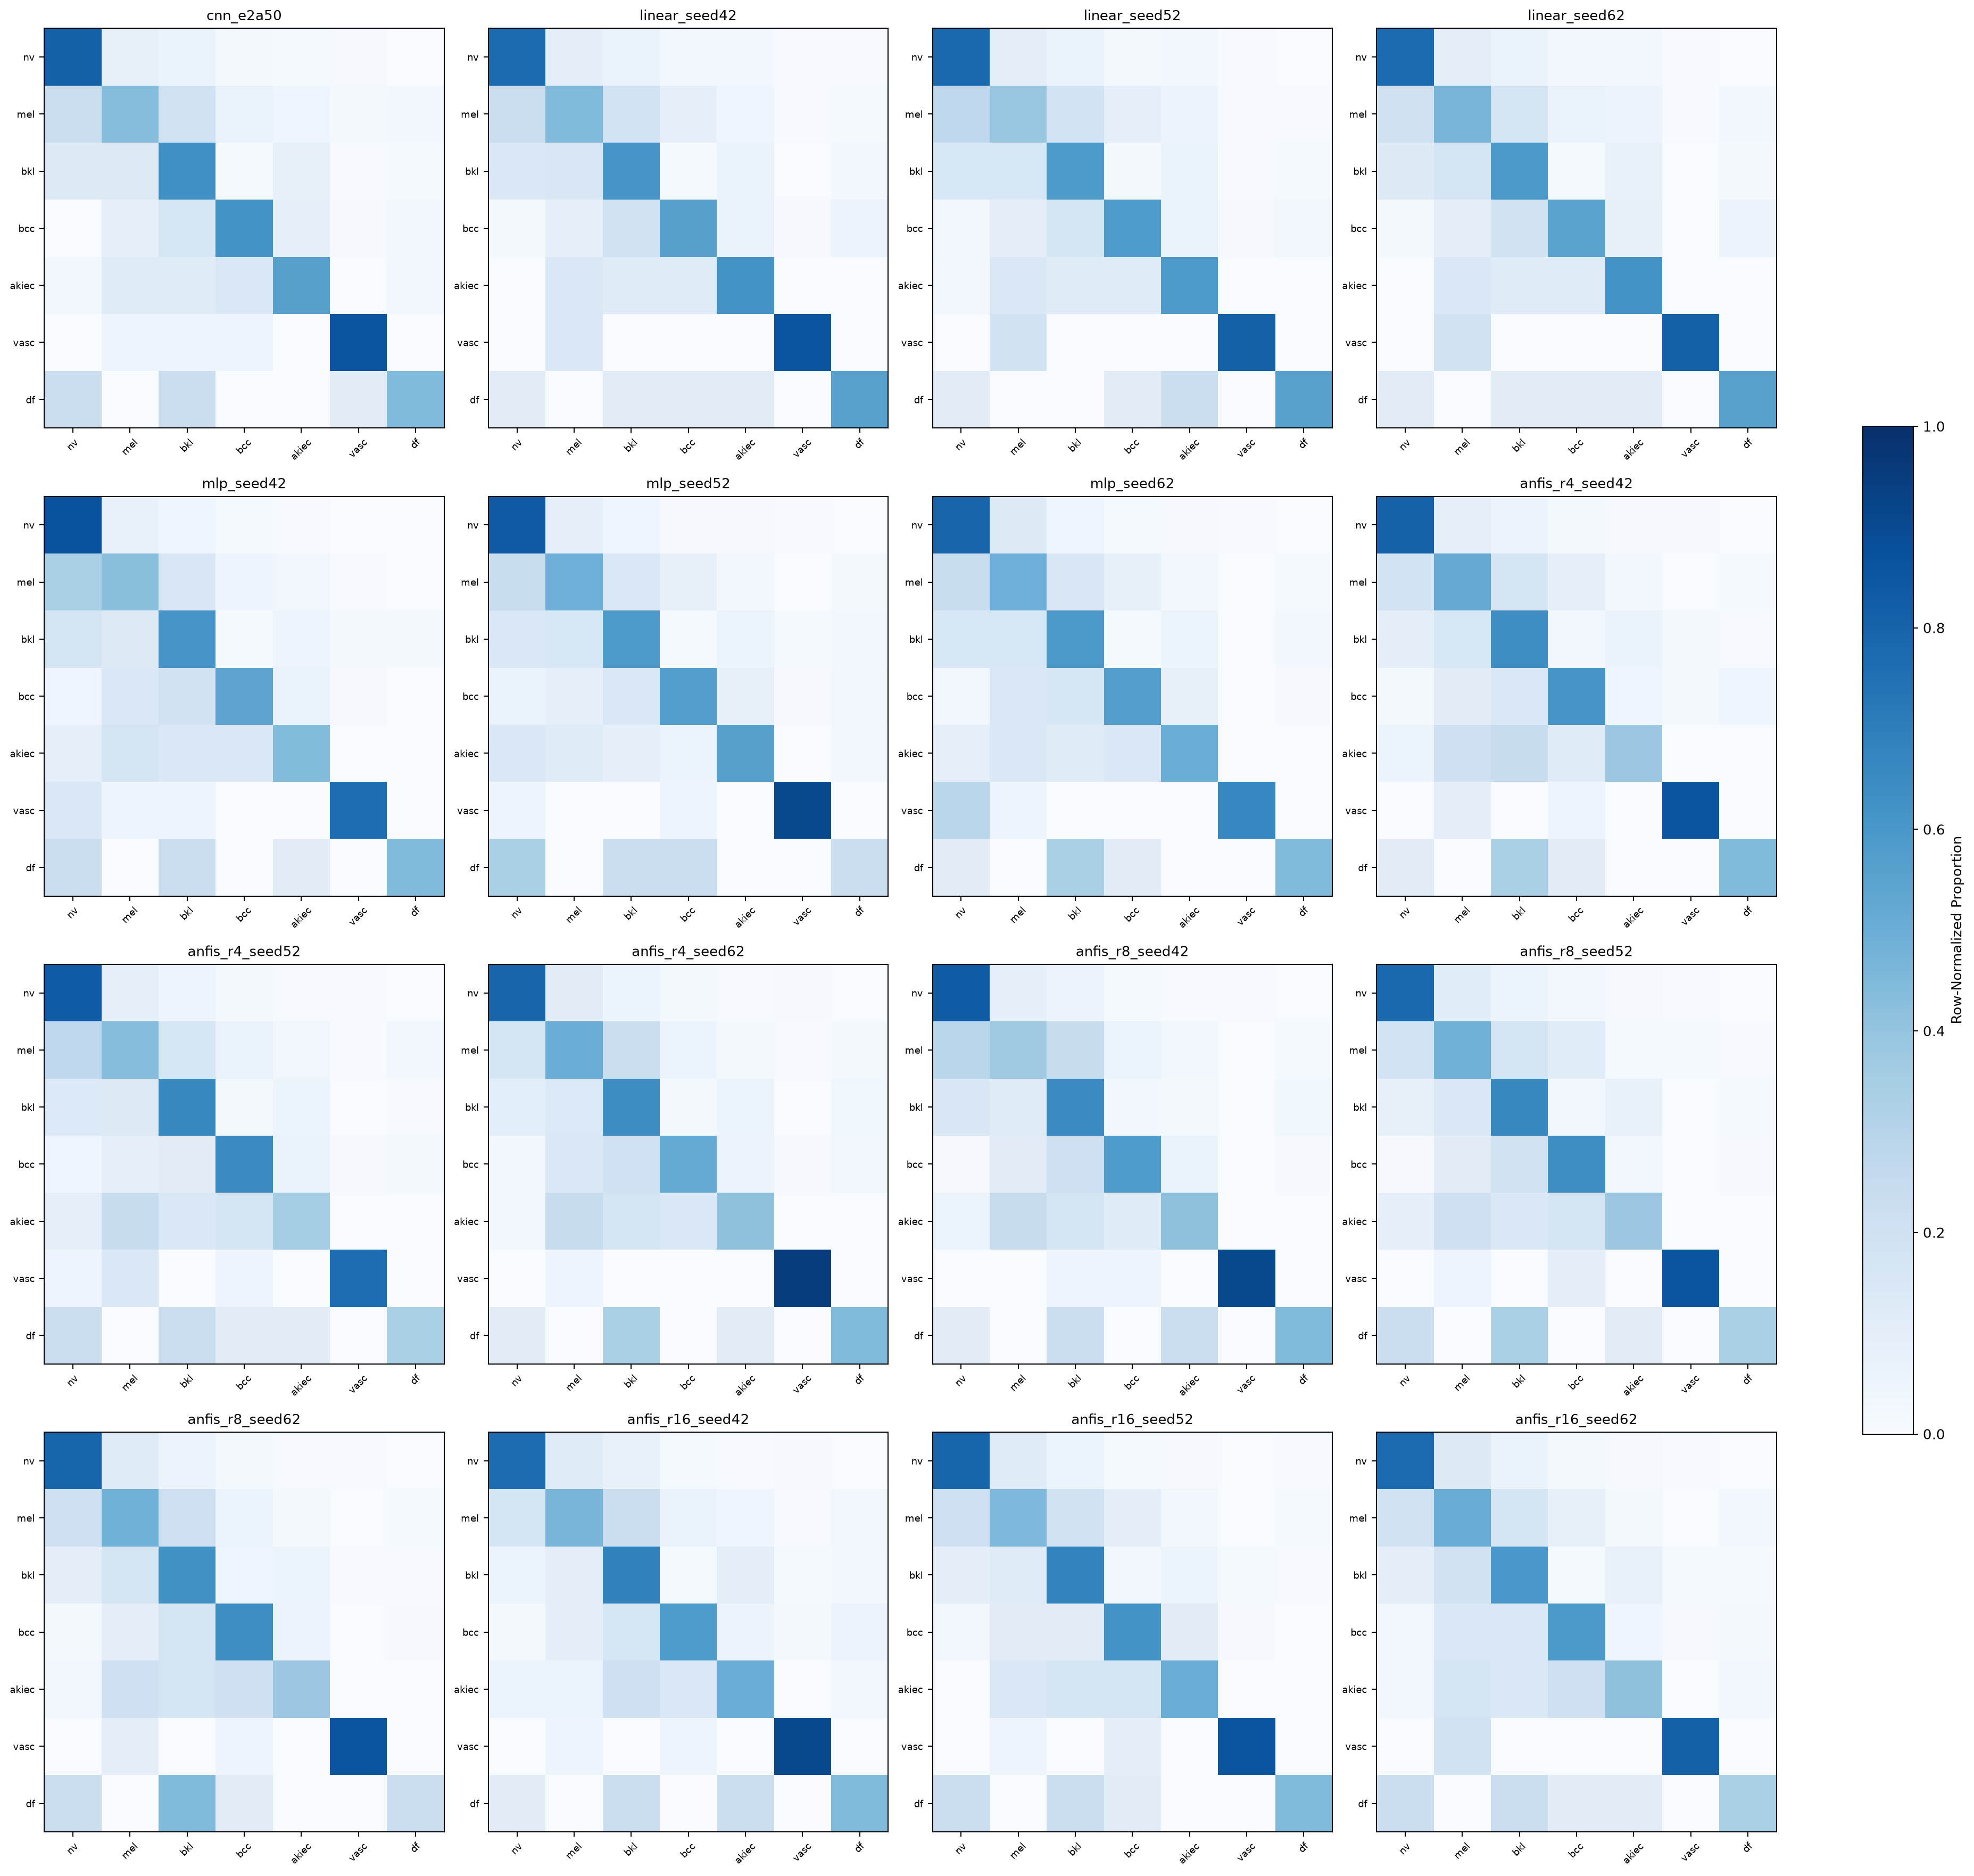

Saved: C:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_09_Model_Comparison_VSCode_Complete\ACIT4620_09_Model_Comparison_VSCode\outputs\ACIT4620_09_Validation_Comparison\additional_figures\04_all_16_confusion_matrices.png


In [12]:

from sklearn.metrics import confusion_matrix

CM_DIR = NEW_FIGURES / "confusion_matrices_all"
CM_DIR.mkdir(exist_ok=True)

all_matrices = {}

for name, data in predictions.items():

    y_true = np.asarray(data["y"])
    y_pred = np.asarray(data["pred"])

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(7)
    )

    all_matrices[name] = cm

    normalized = cm / np.maximum(
        cm.sum(axis=1, keepdims=True),
        1
    )

    for kind, matrix, vmax in [
        ("counts", cm, 974),
        ("normalized", normalized, 1)
    ]:

        fig, ax = plt.subplots(figsize=(8, 7))

        im = ax.imshow(
            matrix,
            cmap="Blues",
            vmin=0,
            vmax=vmax
        )

        ax.set_xticks(range(7), CLASSES)
        ax.set_yticks(range(7), CLASSES)

        ax.set_xlabel("Predicted Diagnosis")
        ax.set_ylabel("True Diagnosis")
        ax.set_title(
            f"{name} — Confusion Matrix ({kind})"
        )

        for i in range(7):
            for j in range(7):
                value = matrix[i, j]

                text = (
                    f"{int(value)}"
                    if kind == "counts"
                    else f"{value:.2f}"
                )

                ax.text(
                    j, i, text,
                    ha="center",
                    va="center",
                    fontsize=9,
                    color=(
                        "white"
                        if value > 0.55 * vmax
                        else "black"
                    )
                )

        fig.colorbar(im, ax=ax)
        fig.tight_layout()

        fig.savefig(
            CM_DIR / f"{name}_{kind}.png",
            dpi=180,
            bbox_inches="tight"
        )

        plt.close(fig)

print("Saved individual matrices for", len(all_matrices), "models")

# Create the 4x4 overview of all 16 models
fig, axes = plt.subplots(
    4, 4,
    figsize=(20, 19),
    constrained_layout=True
)

for ax, (name, cm) in zip(
    axes.flat,
    all_matrices.items()
):
    normalized = cm / np.maximum(
        cm.sum(axis=1, keepdims=True),
        1
    )

    im = ax.imshow(
        normalized,
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    ax.set_title(name, fontsize=10)

    ax.set_xticks(
        range(7), CLASSES,
        fontsize=7, rotation=45
    )

    ax.set_yticks(
        range(7), CLASSES,
        fontsize=7
    )

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.55,
    label="Row-Normalized Proportion"
)

path = NEW_FIGURES / "04_all_16_confusion_matrices.png"
fig.savefig(path, dpi=185, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(path)))
print("Saved:", path)


In [13]:

import shutil

archive = shutil.make_archive(
    str(
        ROOT / "outputs" /
        "ACIT4620_09_Validation_Comparison_Outputs"
    ),
    "zip",
    root_dir=ROOT / "outputs",
    base_dir="ACIT4620_09_Validation_Comparison"
)

print("Updated backup ZIP:", archive)
print("All additional visualizations saved.")


Updated backup ZIP: C:\Users\grela\OneDrive\Desktop\OSLOMET\COMPUTATIONAL INTELLIGENCE\FOR FINAL REPORT\CODE\Notebook_09_Model_Comparison_VSCode_Complete\ACIT4620_09_Model_Comparison_VSCode\outputs\ACIT4620_09_Validation_Comparison_Outputs.zip
All additional visualizations saved.


### 8. What this establishes—and what it does not

- **RQ1 (data-centric):** E1/E2a/E2b experiments are complementary, but causal effects of class weighting versus longer training have not been fully isolated here.
- **RQ2 (predictive comparison):** Controlled shared E2a-50 features; linear, MLP and ANFIS all evaluated on the same 1,441 validation images. Report both selected checkpoint performance and three-seed means; do not claim ANFIS is universally superior.
- **RQ3 (explainability):** Rule-contribution and rule-ablation outputs are in E4. ANFIS-aware image-level Grad-CAM/occlusion remain required in a separate notebook.
- **RQ4 (cost):** Parameter counts and historical head-only training times are available. Matched full CNN+classifier inference, runtime and memory testing remain required.

**Do not open the locked 1,458-image test split until final model-selection decisions are fixed.**

**GitHub:** Place this notebook, Python script, `inputs/` and `outputs/` under `experiments/e5_model_comparison/` on a new feature branch. Review public repository privacy; the E3 source configuration included a local path which has been redacted in this Notebook 09 input bundle.
